# EVALUACIÓN INDIVIDUAL 3

Diego Eduardo Monja Zagaceta 20242642

# 1. Instalación e importación de librerías necesarias

In [105]:
!pip install pysal

In [140]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import esda

from libpysal.graph import Graph

# 2. Preprocesamiento de data

In [107]:
#Leemos los datos y los revisamos
peruDataLink = "https://github.com/CienciaDeDatosEspacial/dataSets/raw/refs/heads/main/PERU/PeruMaps.gpkg"
peru_distritos=gpd.read_file(peruDataLink, layer="good_geom")

In [108]:
peru_distritos.head()

,DEPARTAMENTO,PROVINCIA,DISTRITO,ubigeo,Poblacion,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
0,Apurimac,ABANCAY,ABANCAY,PE030101,56871,0.600375,78.865450,15.8,2.9,"MULTIPOLYGON (((-72.93158 -13.55616, -72.9314 ..."
1,Ancash,BOLOGNESI,ABELARDO PARDO LEZAMETA,PE020502,1263,0.434687,50.434603,33.6,25.4,"MULTIPOLYGON (((-77.1474 -10.29675, -77.14643 ..."
2,Arequipa,CARAVELI,ACARI,PE040302,3010,0.634185,56.273614,26.2,8.8,"MULTIPOLYGON (((-74.61542 -15.13728, -74.61174..."
3,Ancash,OCROS,ACAS,PE021402,1057,0.469140,72.527156,70.4,67.6,"MULTIPOLYGON (((-77.26312 -10.43537, -77.26356..."
4,Cusco,PARURO,ACCHA,PE081002,3839,0.300626,64.586647,28.6,11.1,"MULTIPOLYGON (((-71.80912 -13.92427, -71.80901..."


In [109]:
# Separamos los distritos designados
departamentos = ["TACNA", "PUNO", "MOQUEGUA"]
peru_elegidos = peru_distritos[peru_distritos["DEPARTAMENTO"].str.upper().isin(departamentos)].copy()
# Reproyectamos para trabajar con distancias en metros
peru_elegidos = peru_elegidos.to_crs(epsg=32719)
peru_distritos = peru_distritos.to_crs(epsg=32719)
#Utilizamos el Ubigeo como identificador único debido a que los distritos pueden repetirse en diferentes provincias o departamentos
peru_elegidos = peru_elegidos.set_index("ubigeo")

#Visualizamos la cantidad de distritos por departamento
print("Número de distritos:", len(peru_elegidos))
print(peru_elegidos["DEPARTAMENTO"].value_counts())

Número de distritos: 158
DEPARTAMENTO
Puno        110
Tacna        28
Moquegua     20
Name: count, dtype: int64


Veamos si las áreas de estudio han sido seleccionadas correctamente

Text(0.5, 1.0, 'Distritos de Tacna, Puno y Moquegua')

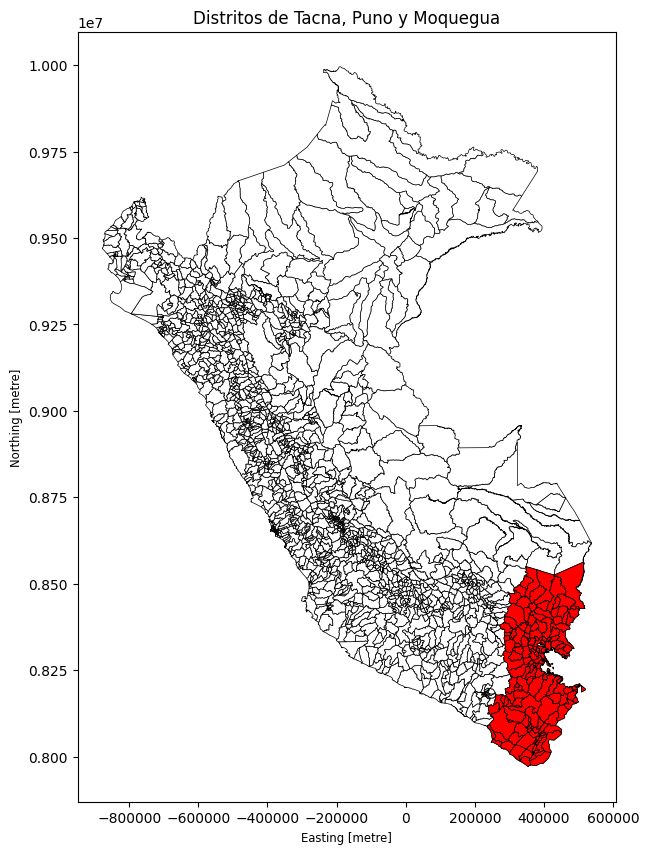

In [110]:
base=peru_distritos.plot(figsize=(10,10), facecolor="white", edgecolor="black", linewidth=0.5)
peru_elegidos.plot(
    ax=base,
    figsize=(10,10),
    facecolor="red",
    edgecolor="black",
    linewidth=0.5
)
plt.title("Distritos de Tacna, Puno y Moquegua")

# 3. Creación de los 4 tipos de vecindarios y su mapa LISA

In [111]:
#Definimos la variable de estudio
variable = "Educ_sec_comp2019_pct"

# a) Rook: Considera que dos distritos son vecinos únicamente cuando comparten un lado.

In [112]:
#Construcción del vecindario Rook
rook = Graph.build_contiguity(peru_elegidos, rook=True)
#Identificamos distritos aislados
print("Distritos aislados:", len(rook.isolates))

Distritos aislados: 2


In [113]:
#Observamos que distritos han sido aislados
rook_aislados = rook.isolates
peru_elegidos.loc[rook.isolates, ["DISTRITO", "DEPARTAMENTO"]]

,DISTRITO,DEPARTAMENTO
focal,,
PE210103,AMANTANI,Puno
PE211302,ANAPIA,Puno


In [114]:
#Los distritos identificados como aislados no presentan vecinos bajo el criterio de contigüidad establecido, por lo que se excluyen del cálculo del índice de Moran Local.
peru_rook = peru_elegidos.drop(index=rook.isolates).copy()
#Reconstruimos el vecindario
rook = Graph.build_contiguity(peru_rook, rook=True)
#Estandarizamos de pesos
rook = rook.transform("r")
#Calculamos el LISA
lisa_rook = esda.Moran_Local(peru_rook[variable], rook)

Observemos el vecindario creado

In [141]:
#Condiciones generales de graficación
general_arguments = dict(
    node_kws=dict(color="red"),
    edge_kws=dict(alpha=0.4, color="blue"),
)

Text(0.5, 1.0, 'Vecindario Rook')

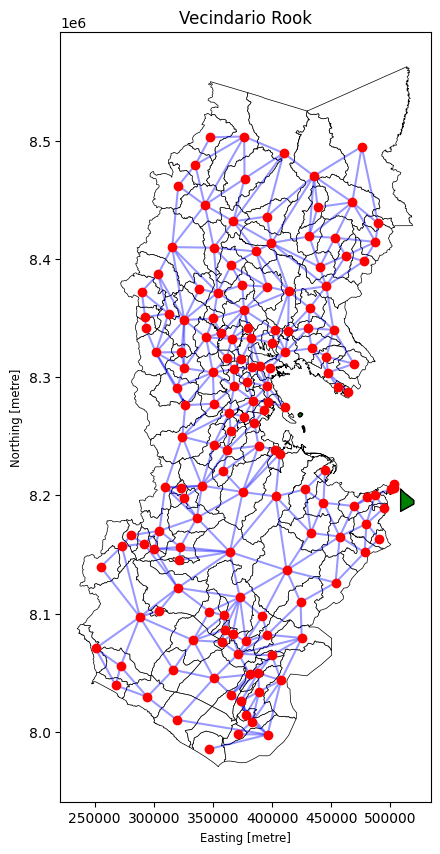

In [142]:
base = peru_elegidos.plot(figsize=(10,10), facecolor="white", edgecolor="black", linewidth=0.5)
rook.plot(ax=base, gdf=peru_rook, **general_arguments)
peru_elegidos.loc[rook_aislados].plot(
    ax=base,
    facecolor="green",
    edgecolor="black"
)
plt.title("Vecindario Rook")

Entonces, adaptamos los cuadrantes de correlación espacial

In [117]:
labels = {
    "Insignificant": "3 no_pattern",
    "Low-Low": "4 coldSpot",
    "High-High": "2 hotSpot",
    "High-Low": "1 hotOutlier",
    "Low-High": "5 coldOutlier"
}

Donde:


1.   Hot Spot (High-High): Distrito con valor alto rodeado de distritos con valores altos
2.   Cold Spot (Low-Low): Distrito con valor bajo rodeado de distritos con valores bajos
3.   Hot Outlier (High-Low): Distrito con valor alto rodeado de distritos con valores bajos
4.   Cold Outlier (Low-High): Distrito con valor bajo rodeado de distritos con valores altos




In [118]:
#Obtenemos los cuadrantes
peru_rook["LISA"] = lisa_rook.get_cluster_labels(crit_value=0.05)
peru_rook.replace({"LISA":labels}, inplace=True)

peru_rook["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,5
2 hotSpot,1
3 no_pattern,143
4 coldSpot,3
5 coldOutlier,4


Creamos el mapa LISA del vecindario Rook

Text(0.5, 1.0, 'Distritos de Tacna, Puno y Moquegua (Vecindario Rook)')

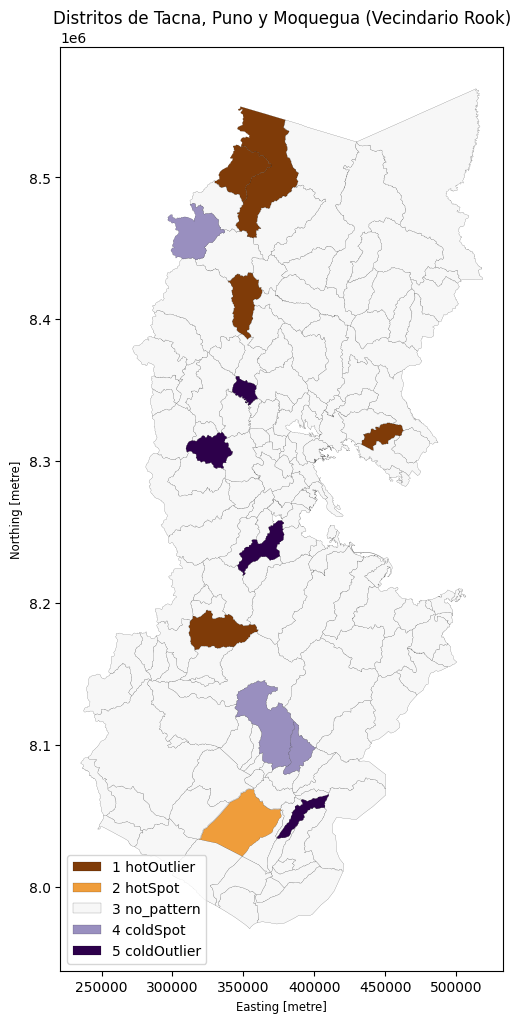

In [119]:
myColMap = plt.get_cmap('PuOr', 5)
# Mapa LISA Rook
peru_rook.plot(
    column="LISA",
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor="black",
    legend=True,
    legend_kwds={"loc": "lower left"},
    figsize=(12,12)
)
plt.title("Distritos de Tacna, Puno y Moquegua (Vecindario Rook)")

# b) Vecindario By Perimeter: Considera como vecinos a los distritos que comparten una frontera y asigna un peso proporcional a la longitud del perímetro compartido. Por ello, los distritos que comparten una frontera más extensa tienen una mayor influencia en la relación espacial.

Repetimos el proceso

In [120]:
#Construcción del vecindario By Perimeter
perimeter = Graph.build_contiguity(peru_elegidos, by_perimeter=True)

#Identificar distritos aislados
print("Distritos aislados:", len(perimeter.isolates))

Distritos aislados: 2


In [121]:
#Observamos que distritos han sido aislados
perimeter_aislados = perimeter.isolates
peru_elegidos.loc[perimeter.isolates, ["DISTRITO", "DEPARTAMENTO"]]

,DISTRITO,DEPARTAMENTO
focal,,
PE210103,AMANTANI,Puno
PE211302,ANAPIA,Puno


In [122]:
#Los distritos identificados como aislados no presentan vecinos bajo el criterio de contigüidad establecido, por lo que se excluyen del cálculo del índice de Moran Local.
peru_perimeter = peru_elegidos.drop(index=perimeter.isolates).copy()

#Reconstruir el vecindario By Perimeter
perimeter = Graph.build_contiguity(peru_elegidos, by_perimeter=True)

#Estandarización de pesos
perimeter = perimeter.transform("r")

#Cálculo del LISA
lisa_perimeter = esda.Moran_Local(peru_perimeter[variable], perimeter)

Text(0.5, 1.0, 'Vecindario por perímetro')

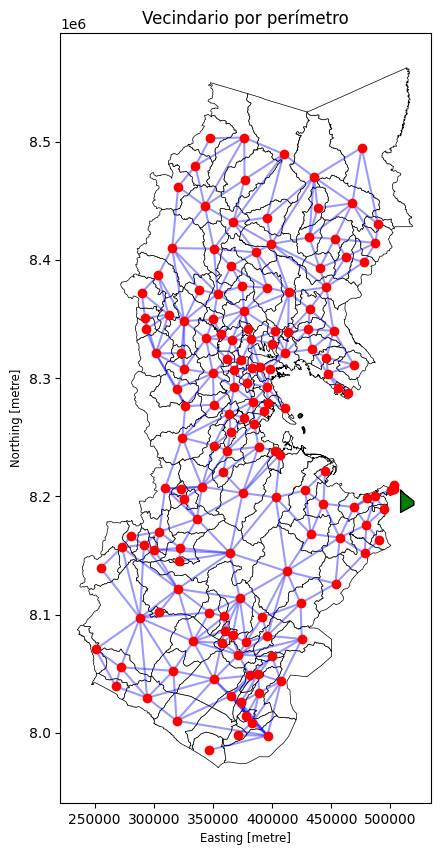

In [143]:
#Visualización del vecindario
base = peru_elegidos.plot(figsize=(10,10), facecolor="white", edgecolor="black", linewidth=0.5)
perimeter.plot(ax=base, gdf=peru_perimeter, **general_arguments)
peru_elegidos.loc[perimeter_aislados].plot(
    ax=base,
    facecolor="green",
    edgecolor="black",
)
plt.title("Vecindario por perímetro")

In [124]:
#Obtenemos los cuadrantes
peru_perimeter["LISA"] = lisa_perimeter.get_cluster_labels(crit_value=0.05)
peru_perimeter.replace({"LISA":labels}, inplace=True)

peru_perimeter["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,4
2 hotSpot,2
3 no_pattern,143
4 coldSpot,4
5 coldOutlier,3


Gráficamos el Mapa LISA del vecindario por perímetro

Text(0.5, 1.0, 'Distritos de Tacna, Puno y Moquegua (Vecindario por perímetro)')

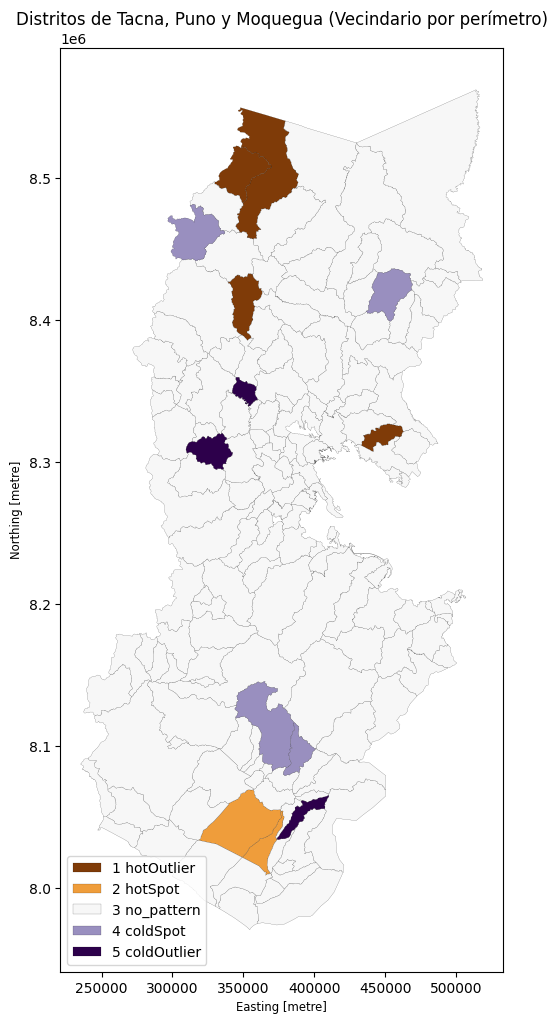

In [125]:
#Mapa LISA by perimeter
peru_perimeter.plot(
    column="LISA",
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor="black",
    legend=True,
    legend_kwds={"loc": "lower left"},
    figsize=(12,12)
)
plt.title("Distritos de Tacna, Puno y Moquegua (Vecindario por perímetro)")

# c) Vecindario KNN (con K=3): Cada distrito tendrá como vecinos a sus tres distritos más cercanos, según la ubicación de sus puntos representativos.

Repetimos nuevamente el proceso

In [126]:
#Construcción del vecindario KNN con k=3
knn = Graph.build_knn(peru_elegidos.representative_point(), k=3)

#Identificar distritos aislados
print("Distritos aislados:", len(knn.isolates))

Distritos aislados: 0


Text(0.5, 1.0, 'Vecindario KNN con K=3')

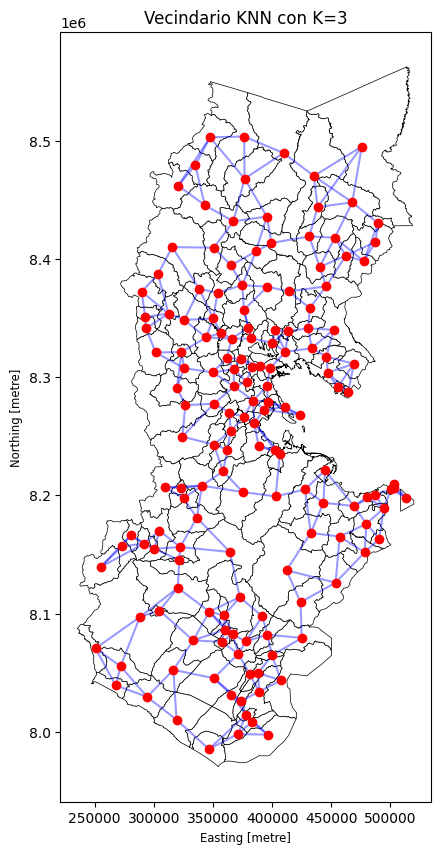

In [127]:
#Visualización del vecindario
base = peru_elegidos.plot(figsize=(10,10), facecolor="white", edgecolor="black", linewidth=0.5)
knn.plot(ax=base, **general_arguments)
plt.title("Vecindario KNN con K=3")

In [128]:
#Como no hay distritos aislados, no es necesario eliminarlos.

#Estandarización de pesos
knn = knn.transform("r")

#Cálculo de Moral Local
lisa_knn = esda.Moran_Local(peru_elegidos[variable], knn)

In [129]:
#Clasificación de resultados
peru_knn = peru_elegidos.copy()
peru_knn["LISA"] = lisa_knn.get_cluster_labels(crit_value=0.05)
peru_knn.replace({"LISA":labels}, inplace=True)

peru_knn["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,4
2 hotSpot,2
3 no_pattern,143
4 coldSpot,4
5 coldOutlier,5


Gráficamos el Mapa LISA del vecindario KNN con K=3

Text(0.5, 1.0, 'Distritos de Tacna, Puno y Moquegua (Vecindario KNN, K=3)')

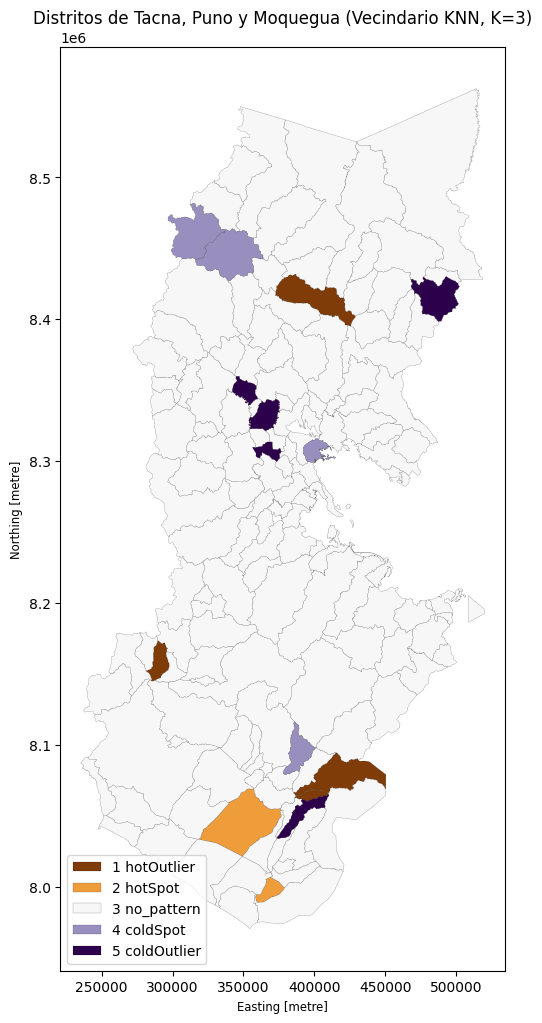

In [130]:
#Mapa LISA KNN (K=3)
peru_knn.plot(
    column="LISA",
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor="black",
    legend=True,
    legend_kwds={"loc": "lower left"},
    figsize=(12,12)
)
plt.title("Distritos de Tacna, Puno y Moquegua (Vecindario KNN, K=3)")

# d) Vecindario por distancia (50 km): Dos distritos serán vecinos cuando la distancia entre sus puntos representativos sea menor o igual a 50 000 metros

Se sigue el mismo proceso una vez más

In [131]:
#Construcción del vecindario por distancia
distancia = Graph.build_distance_band(peru_elegidos.representative_point(), threshold=50000)

#Identificar distritos aislados
print("Distritos aislados:", len(distancia.isolates))

Distritos aislados: 0


Text(0.5, 1.0, 'Vecindario por diatancia (50 km)')

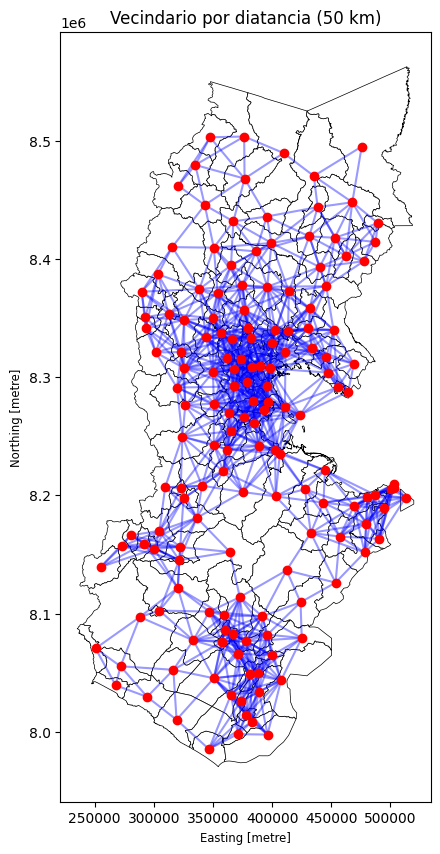

In [132]:
#Visualización del vecindario
base = peru_elegidos.plot(figsize=(10,10), facecolor="white", edgecolor="black", linewidth=0.5)
distancia.plot(ax=base, **general_arguments)
plt.title("Vecindario por distancia (50 km)")

In [133]:
#Como no hay distritos aislados, no es necesario eliminarlos.

#Estandarización de pesos
distancia = distancia.transform("r")

#Cálculo de Moral Local
lisa_distancia = esda.Moran_Local(peru_elegidos[variable], distancia)

In [134]:
#Clasificación de resultados
peru_distancia = peru_elegidos.copy()
peru_distancia["LISA"] = lisa_distancia.get_cluster_labels(crit_value=0.05)
peru_distancia.replace({"LISA":labels}, inplace=True)

peru_distancia["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,1
2 hotSpot,6
3 no_pattern,143
4 coldSpot,2
5 coldOutlier,6


Gráficamos el Mapa LISA del vecindario por distancia (50 km)

Text(0.5, 1.0, 'Distritos de Tacna, Puno y Moquegua (Vecindad por distancia (50 km))')

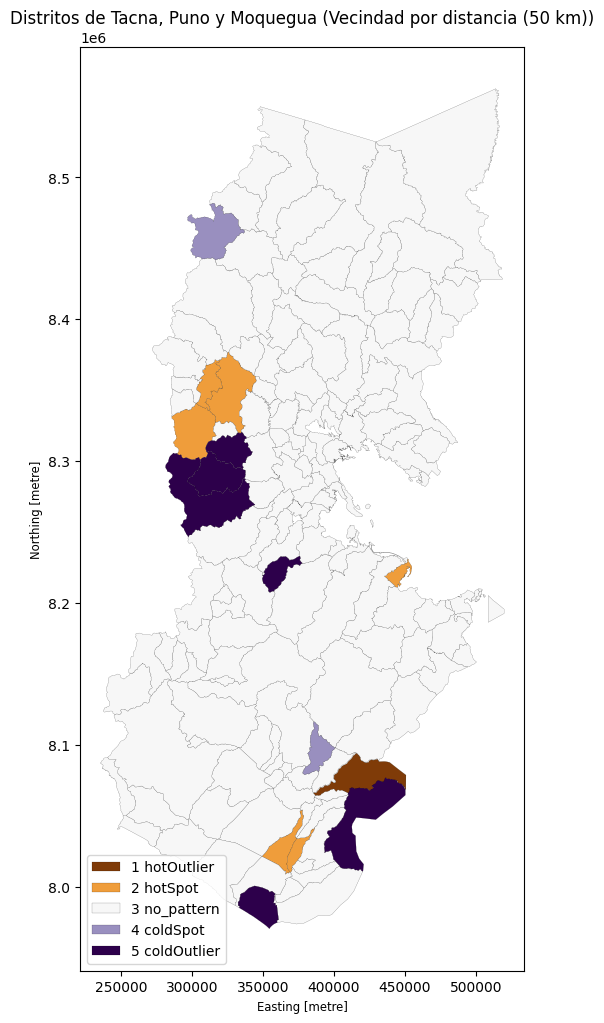

In [135]:
#Mapa LISA Distancia 50 km
peru_distancia.plot(
    column="LISA",
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor="black",
    legend=True,
    legend_kwds={"loc": "lower left"},
    figsize=(12,12)
)
plt.title("Distritos de Tacna, Puno y Moquegua (Vecindad por distancia (50 km))")

# 4. Finalmente, se compara porcentualmente los 4 mapas creados a través de la cantidad de distritos clasificados en las categorías definidas anteriormente

In [144]:
# Comparación porcentual de las categorías LISA
porcentajes = {
    "Rook": peru_rook["LISA"].value_counts(normalize=True) * 100,
    "By Perimeter": peru_perimeter["LISA"].value_counts(normalize=True) * 100,
    "KNN": peru_knn["LISA"].value_counts(normalize=True) * 100,
    "Distancia": peru_distancia["LISA"].value_counts(normalize=True) * 100
}

tabla_porcentajes = pd.DataFrame(porcentajes).fillna(0).round(2)

display(tabla_porcentajes)

,Rook,By Perimeter,KNN,Distancia
LISA,,,,
1 hotOutlier,3.21,2.56,2.53,0.63
2 hotSpot,0.64,1.28,1.27,3.80
3 no_pattern,91.67,91.67,90.51,90.51
4 coldSpot,1.92,2.56,2.53,1.27
5 coldOutlier,2.56,1.92,3.16,3.80
